In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pydot
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
tf.keras.utils.set_random_seed(SEED)


Nạp dữ liệu

In [ ]:
NPZ_PATH = "fashion_96x72.npz"

d = np.load(NPZ_PATH)
X_train, y_train = d["X_train"], d["y_train"]
X_val,   y_val   = d["X_val"],   d["y_val"]
X_test,  y_test  = d["X_test"],  d["y_test"]
class_names = [str(c) for c in d["class_names"]]
NUM_CLASSES = len(class_names)
INPUT_SHAPE = X_train.shape[1:]          # (96, 72, 3)

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)
print("Kiểu dữ liệu:", X_train.dtype, "| Input shape:", INPUT_SHAPE)
print("Các lớp:", class_names)

# Class weights balanced sự chú ý đến lớp ít mẫu hơn
w = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = dict(enumerate(w))
print({class_names[k]: round(float(v), 2) for k, v in class_weight.items()})

Train: (16364, 96, 72, 3) | Val: (3507, 96, 72, 3) | Test: (3507, 96, 72, 3)
Kiểu dữ liệu: uint8 | Input shape: (96, 72, 3)
Các lớp: ['Casual Shoes', 'Flip Flops', 'Handbags', 'Heels', 'Jeans', 'Kurtas', 'Shirts', 'Sports Shoes', 'Tops', 'Tshirts']
{'Casual Shoes': 0.82, 'Flip Flops': 2.55, 'Handbags': 1.33, 'Heels': 1.77, 'Jeans': 3.84, 'Kurtas': 1.27, 'Shirts': 0.73, 'Sports Shoes': 1.15, 'Tops': 1.33, 'Tshirts': 0.33}


Data augmentation (chỉ hoạt động khi train)

In [4]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1, value_range=(0, 255)),
], name="data_augmentation")

Kiến trúc Complex CNN

In [ ]:
def conv_block(x, filters, dropout, name):
    """Một khối: [Conv-BN-ReLU] x 2 -> MaxPool -> Dropout."""
    for i in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                          name=f"{name}_conv{i+1}")(x)
        x = layers.BatchNormalization(name=f"{name}_bn{i+1}")(x)
        x = layers.Activation("relu", name=f"{name}_relu{i+1}")(x)
    x = layers.MaxPooling2D(2, name=f"{name}_pool")(x)
    x = layers.Dropout(dropout, name=f"{name}_drop")(x)
    return x


def build_complex_cnn(input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES):
    inputs = layers.Input(shape=input_shape, name="image")
    x = data_augmentation(inputs)                    # chỉ tác dụng khi train
    x = layers.Rescaling(1.0 / 255, name="rescale")(x)

    x = conv_block(x, 32,  0.10, "block1")           # 96x72 -> 48x36
    x = conv_block(x, 64,  0.20, "block2")           # -> 24x18
    x = conv_block(x, 128, 0.30, "block3")           # -> 12x9
    x = conv_block(x, 256, 0.40, "block4")           # -> 6x4

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(256, activation="relu", name="fc")(x)
    x = layers.Dropout(0.5, name="fc_drop")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="output")(x)
    return models.Model(inputs, outputs, name="complex_cnn")


model = build_complex_cnn()
model.summary()

Model: "complex_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 96, 72, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 96, 72, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 96, 72, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu1 (Activation)       │ (None, 96, 72, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 96, 72, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 96, 72, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu2 (Activation)       │ (None, 96, 72, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 48, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_drop (Dropout)           │ (None, 48, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 48, 36, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 48, 36, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu1 (Activation)       │ (None, 48, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 48, 36, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 48, 36, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu2 (Activation)       │ (None, 48, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 24, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_drop (Dropout)           │ (None, 24, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 24, 18, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 24, 18, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu1 (Activation)       │ (None, 24, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 24, 18, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 24, 18, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu2 (Activation)       │ (None, 24, 18, 128)    │             

 Total params: 1,243,498 (4.74 MB)

 Trainable params: 1,241,578 (4.74 MB)

 Non-trainable params: 1,920 (7.50 KB)

Training

In [ ]:
EPOCHS = 60         
BATCH_SIZE = 64

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    callbacks.ModelCheckpoint("complex_cnn.keras", monitor="val_loss", save_best_only=True, verbose=0),
]

In [8]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=cbs,
    verbose=2,
)

Epoch 1/60
256/256 - 350s - 1s/step - accuracy: 0.5232 - loss: 1.1764 - val_accuracy: 0.3376 - val_loss: 2.2169 - learning_rate: 0.0010
Epoch 2/60
256/256 - 422s - 2s/step - accuracy: 0.6998 - loss: 0.6877 - val_accuracy: 0.5880 - val_loss: 1.0390 - learning_rate: 0.0010
Epoch 3/60
256/256 - 290s - 1s/step - accuracy: 0.7505 - loss: 0.5568 - val_accuracy: 0.4676 - val_loss: 1.6900 - learning_rate: 0.0010
Epoch 4/60
256/256 - 320s - 1s/step - accuracy: 0.7823 - loss: 0.4901 - val_accuracy: 0.6595 - val_loss: 0.8271 - learning_rate: 0.0010
Epoch 5/60
256/256 - 289s - 1s/step - accuracy: 0.7993 - loss: 0.4442 - val_accuracy: 0.7020 - val_loss: 0.7706 - learning_rate: 0.0010
Epoch 6/60
256/256 - 290s - 1s/step - accuracy: 0.8154 - loss: 0.4090 - val_accuracy: 0.7642 - val_loss: 0.6588 - learning_rate: 0.0010
Epoch 7/60
256/256 - 282s - 1s/step - accuracy: 0.8238 - loss: 0.3780 - val_accuracy: 0.6287 - val_loss: 0.9951 - learning_rate: 0.0010
Epoch 8/60
256/256 - 284s - 1s/step - accuracy: 

5. Learning curves

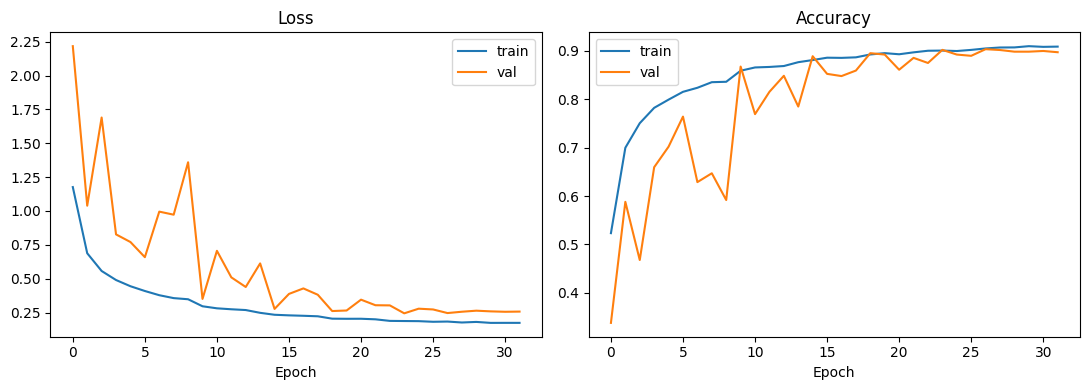

Epoch tốt nhất (val_loss thấp nhất): 24
Val accuracy tại epoch tốt nhất: 0.9022


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig("complex_cnn_curves.png", dpi=150)
plt.show()

best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Epoch tốt nhất (val_loss thấp nhất): {best_epoch}")
print(f"Val accuracy tại epoch tốt nhất: {history.history['val_accuracy'][best_epoch-1]:.4f}")

6. Đánh giá trên tập validation

In [10]:
val_prob = model.predict(X_val, batch_size=128, verbose=0)
val_pred = val_prob.argmax(axis=1)
print("Val accuracy:", round(accuracy_score(y_val, val_pred), 4))
print(classification_report(y_val, val_pred, target_names=class_names, digits=3, zero_division=0))

Val accuracy: 0.9022
              precision    recall  f1-score   support

Casual Shoes      0.938     0.714     0.811       427
  Flip Flops      0.971     0.957     0.964       138
    Handbags      0.996     0.992     0.994       264
       Heels      0.941     0.960     0.950       199
       Jeans      0.989     0.978     0.983        91
      Kurtas      0.947     0.967     0.957       276
      Shirts      0.962     0.938     0.950       482
Sports Shoes      0.706     0.938     0.806       305
        Tops      0.666     0.867     0.753       264
     Tshirts      0.962     0.896     0.928      1061

    accuracy                          0.902      3507
   macro avg      0.908     0.921     0.910      3507
weighted avg      0.916     0.902     0.904      3507



Đánh giá cuối cùng trên tập test (chỉ chạy MỘT lần)

In [11]:
test_prob = model.predict(X_test, batch_size=128, verbose=0)
test_pred = test_prob.argmax(axis=1)
np.save("complex_cnn_test_prob.npy", test_prob)

acc = accuracy_score(y_test, test_pred)
p_m, r_m, f_m, _ = precision_recall_fscore_support(y_test, test_pred, average="macro", zero_division=0)
p_w, r_w, f_w, _ = precision_recall_fscore_support(y_test, test_pred, average="weighted", zero_division=0)

print(f"Accuracy          : {acc:.4f}")
print(f"Macro    P / R / F1: {p_m:.4f} / {r_m:.4f} / {f_m:.4f}")
print(f"Weighted P / R / F1: {p_w:.4f} / {r_w:.4f} / {f_w:.4f}")
print()
print(classification_report(y_test, test_pred, target_names=class_names, digits=3, zero_division=0))

Accuracy          : 0.9068
Macro    P / R / F1: 0.9083 / 0.9231 / 0.9114
Weighted P / R / F1: 0.9180 / 0.9068 / 0.9080

              precision    recall  f1-score   support

Casual Shoes      0.944     0.712     0.812       427
  Flip Flops      0.957     0.971     0.964       137
    Handbags      0.989     0.992     0.991       264
       Heels      0.935     0.944     0.940       198
       Jeans      0.989     0.989     0.989        91
      Kurtas      0.927     0.964     0.945       277
      Shirts      0.955     0.925     0.940       482
Sports Shoes      0.720     0.958     0.822       306
        Tops      0.699     0.860     0.772       265
     Tshirts      0.968     0.915     0.941      1060

    accuracy                          0.907      3507
   macro avg      0.908     0.923     0.911      3507
weighted avg      0.918     0.907     0.908      3507



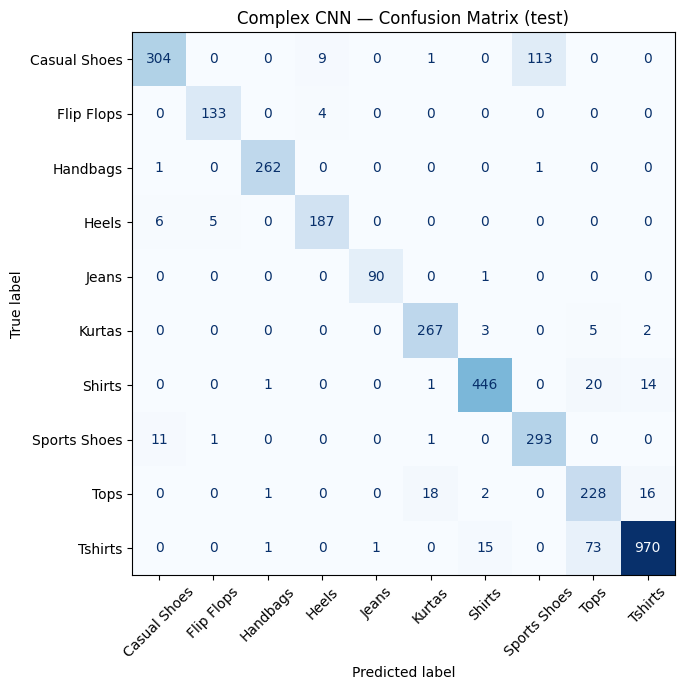

Casual Shoes -> bị đoán thành Sports Shoes: 113 ảnh
Tshirts -> bị đoán thành Tops: 73 ảnh
Shirts -> bị đoán thành Tops: 20 ảnh
Tops -> bị đoán thành Kurtas: 18 ảnh
Tops -> bị đoán thành Tshirts: 16 ảnh


In [12]:
cm = confusion_matrix(y_test, test_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
ax.set_title("Complex CNN — Confusion Matrix (test)")
plt.tight_layout()
plt.savefig("complex_cnn_confusion_matrix.png", dpi=150)
plt.show()

# Các cặp lớp bị nhầm nhiều nhất (để nhận xét trong báo cáo)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm_off.ravel())[:5], cm_off.shape))[0]
for t, p in top:
    print(f"{class_names[t]} -> bị đoán thành {class_names[p]}: {cm_off[t, p]} ảnh")

load Model và dự đoán trên ảnh mới


In [ ]:
# Nạp mô hình từ file đã lưu và dùng nó để dự đoán (không cần train lại)
loaded_model = tf.keras.models.load_model("complex_cnn.keras")

#  Dự đoán trên tập test bằng mô hình nạp từ file
prob = loaded_model.predict(X_test, batch_size=128, verbose=0)
pred = prob.argmax(axis=1)
print("Test accuracy (mô hình nạp từ file):", round(accuracy_score(y_test, pred), 4))

# Dự đoán cho MỘT ảnh mới (ảnh sản phẩm bất kỳ, tự resize về 96x72)
from PIL import Image
IMG_H, IMG_W = 96, 72

def predict_image(path, model=loaded_model, top=3):
    with Image.open(path) as im:
        x = np.asarray(im.convert("RGB").resize((IMG_W, IMG_H)), dtype="uint8")[None]
    p = model.predict(x, verbose=0)[0]
    print("Dự đoán cho", path)
    for i in p.argsort()[::-1][:top]:
        print(f"  {class_names[i]:<14} {p[i]*100:5.1f}%")

predict_image("Shirt.jpg")

Test accuracy (mô hình nạp từ file): 0.9068
Dự đoán cho Shirt.jpg
  Shirts          74.8%
  Tshirts         24.2%
  Kurtas           0.7%
